In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [3]:
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [4]:
df.columns

Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')

In [5]:
df.shape

(23486, 11)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


Calculate summary statistics

In [7]:
numeric_columns = df.select_dtypes(include="number")

summary = pd.DataFrame({
    "mean" : numeric_columns.mean(),
    "median" : numeric_columns.median(),
    "varince" : numeric_columns.var()
})

In [8]:
summary

,mean,median,varince
Unnamed: 0,11742.500000,11742.5,4.596797e+07
Clothing ID,918.118709,936.0,4.133048e+04
Age,43.198544,41.0,1.507872e+02
Rating,4.196032,5.0,1.232168e+00
Recommended IND,0.822362,1.0,1.460888e-01
Positive Feedback Count,2.535936,1.0,3.251510e+01


Find customer insights

In [9]:
avg_rating = df["Rating"].mean()

median_rating = df["Rating"].median()

department = df["Department Name"].mode()[0]

recommend_percent = df["Recommended IND"].mean()*100


In [10]:
print("Avg rating:",avg_rating)
print("Median rating:",median_rating)
print("most common department:",department)
print("Percentage of customers recommending products:",recommend_percent,"%")

Avg rating: 4.196031678446734
Median rating: 5.0
most common department: Tops
Percentage of customers recommending products: 82.23622583666865 %


Perform simple NLP on customer reviews

In [11]:
reviews = df['Review Text'].dropna().astype(str).str.lower()

positive_words = ["good","great","love","beautiful","perfect","comfortable","soft","excellent","nice","best"]
negative_words = ["bad","poor","hate","small","large","cheap","disappointed","uncomfortable","return","wrong"]

positive_count = 0
negative_count = 0

for review in reviews:
    for word in positive_words:
        positive_count += review.count(word)

    for word in negative_words:
        negative_count += review.count(word)

print("positive count:",positive_count)
print("negative count:",negative_count)

positive count: 39751
negative count: 12773


Generate an automatic human-readable report

In [12]:
report = "Women's clothinng data analysis report\n"

report += "total review:"+str(len(df)) + "\n"
report += "avg rating:"+str(avg_rating) + "\n"
report += "median rating:"+str(median_rating) + "\n"
report += "most common department:"+str(department) + "\n"
report += "revommendation rate:"+str(recommend_percent) + "%\n"
report += "positive words:"+str(positive_count) + "\n"
report += "negative words:"+str(negative_count) + "\n"

print(report)

Women's clothinng data analysis report
total review:23486
avg rating:4.196031678446734
median rating:5.0
most common department:Tops
revommendation rate:82.23622583666865%
positive words:39751
negative words:12773



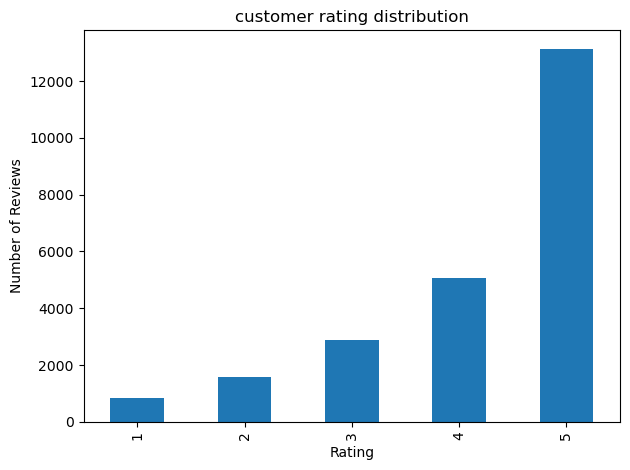

In [13]:
df["Rating"].value_counts().sort_index().plot(kind="bar",title="customer rating distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [14]:
with open("clothing_analysis_report.txt","w",encoding="utf-8")as file:
    file.write(report)

print("Report saved successfully!!")

Report saved successfully!!
